# Figure 2 extended, the bias with binning a continuous variable

In [374]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

current_file_path = Path().resolve().parent
current_file_path

PosixPath('/home/mag/variance-analysis')

In [403]:
import numpy as np

min_rate = 5.0
max_rate = 35.0
beta0     = np.log(min_rate)
amplitude = np.log(max_rate) - beta0

mu_diff, sigma = 0.0, 0.1
mu = 0.4
lo, hi = 0.0, 1.0
num_bins = 100
N = 90_000
seed = 0

theta_deg = 10.0         
theta = np.deg2rad(theta_deg)
use_wrap = False       

discrete_sample = True

def _wrap_diff(d):
    return np.abs((d + 0.5) % 1.0 - 0.5)

def diag_tuning(s1, s2, mu_diff, sigma, amp, wrap=True):
    delta = (s1 - s2) - mu_diff
    delta = _wrap_diff(delta) if wrap else np.abs(delta)
    return amp * np.exp(-0.5 * (delta / sigma) ** 2)

def column_tuning(a, mu, sigma, amp):
    delta = np.abs(a - mu)
    return amp * np.exp(-(delta**2) / (2 * sigma**2))

def rotated_tuning(s1, s2, c, theta, sigma, amp, wrap=False):
    """
    Gaussian ridge around the line obtained by rotating x=c by angle theta (radians)
    about (c,c). 0 rad -> x=c; pi/4 -> x=y.
    NOTE: Uses local shifted coords; does NOT mutate s1/s2.
    """
    if wrap:
        d1 = ((s1 - c + 0.5) % 1.0) - 0.5   # in [-0.5, 0.5)
        d2 = ((s2 - c + 0.5) % 1.0) - 0.5
    else:
        d1 = s1 - c
        d2 = s2 - c
    ct, st = np.cos(theta), np.sin(theta)
    u = d1 * ct - d2 * st
    return amp * np.exp(-0.5 * (u / sigma) ** 2)

rng = np.random.default_rng(seed)
s1 = rng.uniform(lo, hi, size=N)
s2 = rng.uniform(lo, hi, size=N)

bin_edges = np.linspace(lo, hi, num_bins + 1)

if discrete_sample: 
    bin_width = (hi - lo) / num_bins
    s1_bin = np.clip(((s1 - lo) / bin_width).astype(int), 0, num_bins - 1)
    s2_bin = np.clip(((s2 - lo) / bin_width).astype(int), 0, num_bins - 1)
    
    s1 = lo + (s1_bin + 0.5) * bin_width  
    s2 = lo + (s2_bin + 0.5) * bin_width

# --- Choose tuning (examples) ---
#tuning = diag_tuning(s1, s2, mu_diff, sigma, amplitude, wrap=False)
#tuning = column_tuning(s1, mu, sigma, amplitude)
tuning = rotated_tuning(s1, s2, c=mu, theta=theta, sigma=sigma, amp=amplitude, wrap=use_wrap)

rates  = np.exp(beta0 + tuning)
spike_counts = rng.poisson(rates)

occ, _, _ = np.histogram2d(s1, s2, bins=[bin_edges, bin_edges])
spk, _, _ = np.histogram2d(s1, s2, bins=[bin_edges, bin_edges], weights=spike_counts)
rate_map = np.divide(spk, occ, out=np.zeros_like(spk), where=occ > 0)


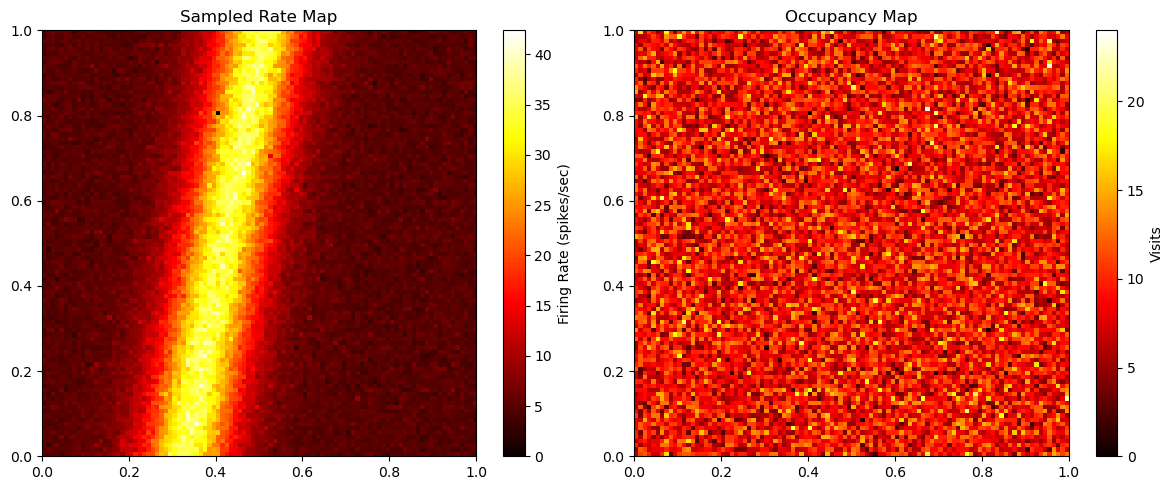

In [404]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Rate map
im1 = axs[0].imshow(rate_map.T, origin='lower', aspect='auto',
                     extent=[bin_edges[0], bin_edges[-1], bin_edges[0], bin_edges[-1]],
                     cmap='hot')
axs[0].set_title("Sampled Rate Map")
fig.colorbar(im1, ax=axs[0], label='Firing Rate (spikes/sec)')

# Occupancy map
im2 = axs[1].imshow(occ.T, origin='lower', aspect='auto',
                     extent=[bin_edges[0], bin_edges[-1], bin_edges[0], bin_edges[-1]],
                     cmap='hot')
axs[1].set_title(f"Occupancy Map")
fig.colorbar(im2, ax=axs[1], label='Visits')

plt.tight_layout()
plt.show()

# just plot the ground truth
# like a three panel thing

In [369]:
max_bin_occ = int(np.max(occ))

raw_visits = np.full((num_bins, num_bins, max_bin_occ), np.nan) 

for s1_i in range(num_bins):
    for s2_i in range(num_bins):
        visits_indexes = (s1 >= bin_edges[s1_i]) & (s1 < bin_edges[s1_i + 1])
        visits_indexes &= (s2 >= bin_edges[s2_i]) & (s2 < bin_edges[s2_i + 1])
        spikes_bin = spike_counts[visits_indexes]
        
        raw_visits[s1_i, s2_i, :len(spikes_bin)] = spikes_bin
        

In [370]:
from src.methods import get_splits, quantify_variance
from tqdm import tqdm

n_splits = 200
est_var = np.zeros((2, n_splits))

for i in tqdm(range(n_splits)):
    total_mean, train_mean, test_mean, _, _ = get_splits(raw_visits[:, :, :, np.newaxis], min_visits=2, cap=False, seed=i)
    est_var[0, i] = quantify_variance(train_mean, test_mean, axis=0)[0]
    est_var[1, i] = quantify_variance(train_mean, test_mean, axis=1)[0]


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:01<00:00, 190.43it/s]


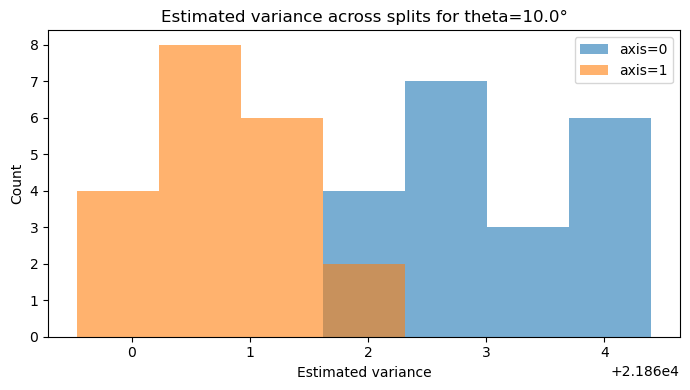

In [402]:
a = est_var[0].ravel()
b = est_var[1].ravel()

bins = np.histogram_bin_edges(np.concatenate([a, b]), bins="auto")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(a, bins=bins, alpha=0.6, label="axis=0")
ax.hist(b, bins=bins, alpha=0.6, label="axis=1")

ax.set_xlabel("Estimated variance")
ax.set_ylabel("Count")              
ax.set_title(f"Estimated variance across splits for theta={theta_deg}°")
ax.legend()
fig.tight_layout()
plt.show()


In [390]:
from sklearn.linear_model import LinearRegression

# collect all of the angles and fit a linear regression to it
degs = [0., 10., 20., 30., 45.]
l = len(degs)

n_splits = 20

angle_ratio = np.zeros(l)
ev_ratio = np.zeros(l)
eps = 1e-12 # ratio padding

for d in range(l):
    theta_deg = degs[d]
    theta = np.deg2rad(theta_deg)
    tuning = rotated_tuning(s1, s2, c=mu, theta=theta, sigma=sigma, amp=amplitude, wrap=use_wrap)

    rates  = np.exp(beta0 + tuning)
    spike_counts = rng.poisson(rates)
    
    occ, _, _ = np.histogram2d(s1, s2, bins=[bin_edges, bin_edges])
    spk, _, _ = np.histogram2d(s1, s2, bins=[bin_edges, bin_edges], weights=spike_counts)
    rate_map = np.divide(spk, occ, out=np.zeros_like(spk), where=occ > 0)

    max_bin_occ = int(np.max(occ))

    raw_visits = np.full((num_bins, num_bins, max_bin_occ), np.nan) 
    
    for s1_i in range(num_bins):
        for s2_i in range(num_bins):
            visits_indexes = (s1 >= bin_edges[s1_i]) & (s1 < bin_edges[s1_i + 1])
            visits_indexes &= (s2 >= bin_edges[s2_i]) & (s2 < bin_edges[s2_i + 1])
            spikes_bin = spike_counts[visits_indexes]
            
            raw_visits[s1_i, s2_i, :len(spikes_bin)] = spikes_bin

    est_var = np.zeros((2, n_splits))
    
    for i in tqdm(range(n_splits)):
        total_mean, train_mean, test_mean, _, _ = get_splits(raw_visits[:, :, :, np.newaxis], min_visits=2, cap=False, seed=i)
        est_var[0, i] = quantify_variance(train_mean, test_mean, axis=0)[0]
        est_var[1, i] = quantify_variance(train_mean, test_mean, axis=1)[0]
    
    Ex = est_var[0].ravel().mean() 
    Ey = est_var[1].ravel().mean() 
    
    theta = np.deg2rad(theta_deg)
    alpha = np.pi/2 - theta
    
    rho_y_over_x = np.tan(alpha) 
    rho_x_over_y = 1.0 / rho_y_over_x 
    
    R_xy = (Ex + eps) / (Ey + eps)   
    R_yx = 1.0 / (R_xy + eps)       

    angle_ratio[d] = rho_x_over_y
    ev_ratio[d] = R_yx


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:00<00:00, 158.64it/s]


0.9259814369835465

In [399]:
angle_ratio = angle_ratio.reshape(-1, 1)
ev_ratio = ev_ratio.reshape(-1, 1)
reg = LinearRegression().fit(angle_ratio, ev_ratio)

reg.score(angle_ratio, ev_ratio), reg.coef_[0][0]

(0.9259814369835465, 1.0081168352997718)